### **1) Import Modules**

In [35]:
import torch
import numpy as np
import matplotlib.pyplot as plt

### **2) Tensors**

In PyTorch, tensors are multidimensional arrays, similar to NumPy arrays, that support automatic differentiation and can be processed on GPUs for efficient computation. Creating tensors and performing operations on them is very similar to working with NumPy arrays, with many functions sharing the same names and syntax. PyTorch supports familiar operations such as indexing, slicing, reshaping, element-wise arithmetic, and matrix multiplication.

In [36]:
# Scalar (0D tensor)
a = torch.tensor(5)

# Vector (1D tensor)
b = torch.tensor([1, 2, 3])

# Matrix (2D tensor)
c = torch.tensor([[1, 2, 3],
                  [4, 5, 6]])

# 3D tensor
d = torch.tensor([[[1, 2], [3, 4]],
                  [[5, 6], [7, 8]]])

print(type(a))
print(a.shape)  # torch.Size([])
print(b.shape)  # torch.Size([3])
print(c.shape)  # torch.Size([2, 3])
print(d.shape)  # torch.Size([2, 2, 2])

<class 'torch.Tensor'>
torch.Size([])
torch.Size([3])
torch.Size([2, 3])
torch.Size([2, 2, 2])


In [37]:
# creating tensors of arbitrary shapes

a = torch.zeros(3, 4)       # 3x4 tensor of zeros
b = torch.ones(2, 3, 4)     # 2x3x4 tensor of ones
c = torch.rand(2, 3)        # 2x3 tensor of random values
d = torch.randn(3, 4)       # 3x4 tensor from standard normal distribution

print(a)
print(b)
print(c)
print(d)

tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]])
tensor([[[1., 1., 1., 1.],
         [1., 1., 1., 1.],
         [1., 1., 1., 1.]],

        [[1., 1., 1., 1.],
         [1., 1., 1., 1.],
         [1., 1., 1., 1.]]])
tensor([[0.5125, 0.7479, 0.7521],
        [0.2946, 0.1529, 0.3706]])
tensor([[-1.3476,  0.5714,  1.0245,  2.0228],
        [ 0.4298,  1.0616,  0.0309,  1.9754],
        [-0.8762,  0.6996,  0.5263, -1.1061]])


In [38]:
# tensor operations and indexing

a = torch.tensor([[1., 2.],
                  [3., 4.]])

b = torch.tensor([[5., 6.],
                  [7., 8.]])

# Element-wise operations
print(a + b)       # Addition
print(a - b)       # Subtraction
print(a * b)       # Multiplication
print(a / b)       # Division
print(a ** 2)      # Exponentiation

# Matrix operations
print(a @ b)       # Matrix multiplication
print(a.T)         # Transpose

# Aggregation operations
print(a.sum())     # Sum of all elements
print(a.mean())    # Mean of all elements
print(a.max())     # Maximum element

# Reshaping
print(a.reshape(4))    # Flatten into 1D tensor
print(a.reshape(1, 4)) # Reshape into 1x4 tensor

# Indexing and slicing
print(a[0, 1])     # Element in row 0, column 1
print(a[0])        # First row
print(a[:, 1])     # Second column

# Element-wise functions
print(torch.exp(a))
print(torch.log(a))
print(torch.sqrt(a))
print(torch.sigmoid(a))
print(torch.relu(a))

tensor([[ 6.,  8.],
        [10., 12.]])
tensor([[-4., -4.],
        [-4., -4.]])
tensor([[ 5., 12.],
        [21., 32.]])
tensor([[0.2000, 0.3333],
        [0.4286, 0.5000]])
tensor([[ 1.,  4.],
        [ 9., 16.]])
tensor([[19., 22.],
        [43., 50.]])
tensor([[1., 3.],
        [2., 4.]])
tensor(10.)
tensor(2.5000)
tensor(4.)
tensor([1., 2., 3., 4.])
tensor([[1., 2., 3., 4.]])
tensor(2.)
tensor([1., 2.])
tensor([2., 4.])
tensor([[ 2.7183,  7.3891],
        [20.0855, 54.5981]])
tensor([[0.0000, 0.6931],
        [1.0986, 1.3863]])
tensor([[1.0000, 1.4142],
        [1.7321, 2.0000]])
tensor([[0.7311, 0.8808],
        [0.9526, 0.9820]])
tensor([[1., 2.],
        [3., 4.]])


### **3) Computing Gradients of Tensors**

One of the most important features of PyTorch is its ability to automatically compute gradients using automatic differentiation. By setting requires_grad=True when creating a tensor, PyTorch tracks operations involving that tensor and allows us to compute gradients using the .backward() method.

In [39]:
# Create a tensor that tracks gradients
x = torch.tensor(3.0, requires_grad=True)

# Define a function: y = x^2 + 2x + 1
y = x**2 + 2*x + 1

# Compute the gradient dy/dx
y.backward()

# Access the gradient
print(x.grad)  # tensor(8.)

tensor(8.)


In [40]:
# Create tensors
x = torch.tensor(2.0)
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)
y = torch.tensor(0.0)

# Forward pass
z = w*x + b
y_hat = torch.sigmoid(z)

# Compute binary cross-entropy loss
loss = -(y*torch.log(y_hat) + (1-y)*torch.log(1-y_hat))

# Retain intermediate gradients
z.retain_grad()
y_hat.retain_grad()

# Backward pass
loss.backward()

# Print results
print("Prediction:", y_hat.item())
print("Loss:", loss.item())
print("Gradient of w:", w.grad)
print("Gradient of b:", b.grad)

# Print gradients
print("dL/dw:", w.grad)
print("dL/db:", b.grad)
print("dL/dz:", z.grad)
print("dL/dy_hat:", y_hat.grad)

Prediction: 0.9990890026092529
Loss: 7.000970363616943
Gradient of w: tensor(1.9982)
Gradient of b: tensor(0.9991)
dL/dw: tensor(1.9982)
dL/db: tensor(0.9991)
dL/dz: tensor(0.9991)
dL/dy_hat: tensor(1097.6980)


In [41]:
# multiple inputs

# Create tensors
x = torch.tensor([2.0, 4.0, 1.0])
w = torch.tensor(0.3, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)
y = torch.tensor([0.0, 1.0, 0.0])

# Forward pass
z = w*x + b
y_hat = torch.sigmoid(z)

# Compute binary cross-entropy loss
loss = -(y*torch.log(y_hat) + (1-y)*torch.log(1-y_hat)).mean()

# Backward pass
loss.backward()

# Print results
print("Predictions:", y_hat)
print("Loss:", loss.item())
print("Gradient of w:", w.grad)
print("Gradient of b:", b.grad)

Predictions: tensor([0.8320, 0.9002, 0.7858], grad_fn=<SigmoidBackward0>)
Loss: 1.1433309316635132
Gradient of w: tensor(0.6836)
Gradient of b: tensor(0.5060)


In [42]:
# vector of parameters

# Create tensors
x = torch.tensor([2.0, 4.0, 1.0])
w = torch.tensor([3.0, 2.0, 1.0], requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)
y = torch.tensor(0.0)

# Forward pass
z = torch.dot(w, x) + b
y_hat = torch.sigmoid(z)

# Compute binary cross-entropy loss
loss = -(y*torch.log(y_hat) + (1-y)*torch.log(1-y_hat))


# Backward pass
loss.backward()

# Print results
print("Predictions:", y_hat)
print("Loss:", loss.item())
print("Gradient of w:", w.grad)
print("Gradient of b:", b.grad)

Predictions: tensor(1.0000, grad_fn=<SigmoidBackward0>)
Loss: 15.942384719848633
Gradient of w: tensor([2.0000, 4.0000, 1.0000])
Gradient of b: tensor(1.0000)


### **4) Generating Noisy Sine Regression Data**

Generate 1,200 observations from $y=\sin(x)+\epsilon$. Randomly split these observations into 70% training, 15% validation, and 15% test sets.


In [43]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import time
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

# Generate 1,200 noisy observations from the same distribution.
num_samples = 1200
X = -3 + 6 * torch.rand(num_samples, 1)
y = torch.sin(X) + 0.35 * torch.randn_like(X)

# Random 70% / 15% / 15% split (no overlap between sets).
indices = torch.randperm(num_samples)
train_end = int(0.70 * num_samples)
val_end = int(0.85 * num_samples)

train_idx = indices[:train_end]
val_idx = indices[train_end:val_end]
test_idx = indices[val_end:]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

print('Train:', X_train.shape, 'Validation:', X_val.shape, 'Test:', X_test.shape)


Device: cpu
Train: torch.Size([840, 1]) Validation: torch.Size([180, 1]) Test: torch.Size([180, 1])


### **5) Visualizing the Data**



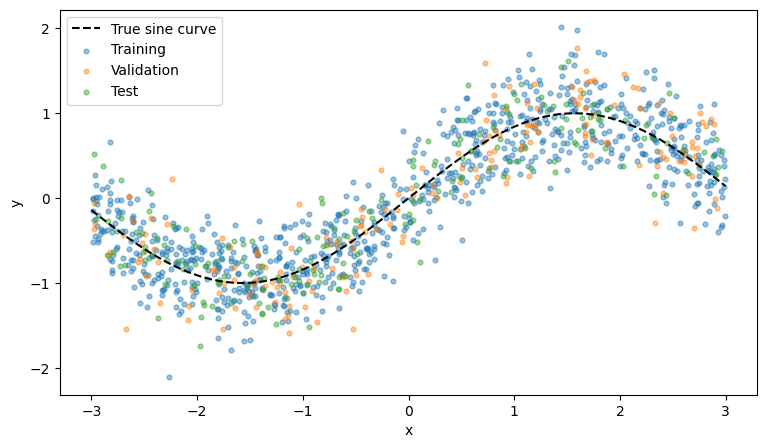

In [44]:
x_plot = torch.linspace(-3, 3, 500).reshape(-1, 1)
plt.figure(figsize=(9, 5))
plt.plot(x_plot.numpy(), torch.sin(x_plot).numpy(), 'k--', label='True sine curve')
plt.scatter(X_train.numpy(), y_train.numpy(), s=12, alpha=0.45, label='Training')
plt.scatter(X_val.numpy(), y_val.numpy(), s=12, alpha=0.45, label='Validation')
plt.scatter(X_test.numpy(), y_test.numpy(), s=12, alpha=0.45, label='Test')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()


### **6) Creating a Training DataLoader**

The `DataLoader` shuffles training observations and creates mini-batches. Validation and test sets can be evaluated in a single forward pass. Training batches are moved to the selected device inside the training loop.


In [45]:
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=32, shuffle=True)


### **7) Defining an MLP**

This model has one input feature, three hidden layers of 128 neurons with ReLU activations, and one **linear** regression output.


In [46]:
class SineMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(1, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        return self.network(x)

model = SineMLP().to(device)
print(model)
print('Trainable parameters:', sum(p.numel() for p in model.parameters()))

SineMLP(
  (network): Sequential(
    (0): Linear(in_features=1, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): ReLU()
    (6): Linear(in_features=128, out_features=1, bias=True)
  )
)
Trainable parameters: 33409


### **8) Specifying the Loss Function and Optimizer**

Mean squared error (MSE) measures regression error; Adam updates the weights based on gradients computed by PyTorch.

In [47]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.005)

### **9) Training and Validation**

For each training batch: predict, compute loss, clear gradients, backpropagate, and update weights. After each epoch, measure validation MSE without computing gradients. Save the model parameters from the epoch with the lowest validation loss.


In [48]:
num_epochs = 600
train_losses = []
val_losses = []
best_val_loss = float('inf')
best_epoch = 0
best_state = None

# Move validation data once, since it is evaluated each epoch.
X_val_device = X_val.to(device)
y_val_device = y_val.to(device)

if device.type == 'cuda':
    torch.cuda.synchronize()
start_time = time.perf_counter()

for epoch in range(num_epochs):
    model.train()
    train_loss_sum = 0.0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        predictions = model(xb)
        loss = loss_fn(predictions, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_loss_sum += loss.item() * len(xb)

    train_losses.append(train_loss_sum / len(X_train))

    model.eval()
    with torch.no_grad():
        val_loss = loss_fn(model(X_val_device), y_val_device).item()
    val_losses.append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        best_state = {name: value.detach().clone() for name, value in model.state_dict().items()}

    if (epoch + 1) % 50 == 0:
        print(f'Epoch {epoch+1:4d}: train MSE={train_losses[-1]:.4f}, val MSE={val_losses[-1]:.4f}')

elapsed = time.perf_counter() - start_time
print(f'Training and validation time: {elapsed:.2f} seconds')
print(f'Lowest validation MSE: {best_val_loss:.4f} (epoch {best_epoch})')

Epoch   50: train MSE=0.1205, val MSE=0.1356
Epoch  100: train MSE=0.1179, val MSE=0.1309
Epoch  150: train MSE=0.1136, val MSE=0.1382
Epoch  200: train MSE=0.1160, val MSE=0.1324
Epoch  250: train MSE=0.1174, val MSE=0.1372
Epoch  300: train MSE=0.1153, val MSE=0.1358
Epoch  350: train MSE=0.1138, val MSE=0.1337
Epoch  400: train MSE=0.1144, val MSE=0.1331
Epoch  450: train MSE=0.1157, val MSE=0.1356
Epoch  500: train MSE=0.1126, val MSE=0.1387
Epoch  550: train MSE=0.1161, val MSE=0.1376
Epoch  600: train MSE=0.1157, val MSE=0.1357
Training and validation time: 20.76 seconds
Lowest validation MSE: 0.1265 (epoch 9)


### **10) Plotting Training and Validation Loss Curves**

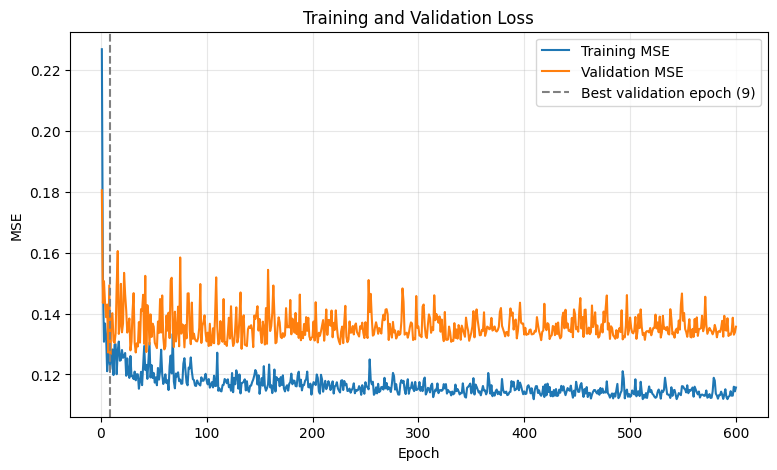

In [49]:
plt.figure(figsize=(9, 5))
plt.plot(range(1, num_epochs + 1), train_losses, label='Training MSE')
plt.plot(range(1, num_epochs + 1), val_losses, label='Validation MSE')
plt.axvline(best_epoch, color='gray', linestyle='--', label=f'Best validation epoch ({best_epoch})')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### **11) Evaluating on the Test Set**

Compare the final model with the checkpoint that achieved the lowest validation MSE.


In [50]:
model.eval()
X_test_device = X_test.to(device)
y_test_device = y_test.to(device)
with torch.no_grad():
    final_test_mse = loss_fn(model(X_test_device), y_test_device).item()

best_model = SineMLP().to(device)
best_model.load_state_dict(best_state)
best_model.eval()
with torch.no_grad():
    best_test_mse = loss_fn(best_model(X_test_device), y_test_device).item()

print(f'Final model test MSE: {final_test_mse:.4f}')
print(f'Best-validation model test MSE: {best_test_mse:.4f}')

Final model test MSE: 0.1189
Best-validation model test MSE: 0.1106


### **12) Visualizing the Learned Curve**

Compare the final model, the best-validation model, the underlying sine curve , and the training points.


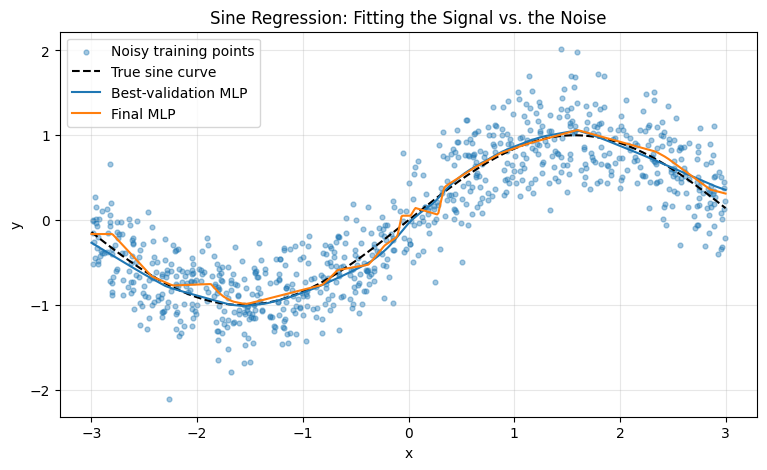

In [51]:
x_grid = torch.linspace(-3, 3, 500).reshape(-1, 1)
model.eval()
best_model.eval()
with torch.no_grad():
    final_predictions = model(x_grid.to(device)).cpu().numpy()
    best_predictions = best_model(x_grid.to(device)).cpu().numpy()

plt.figure(figsize=(9, 5))
plt.scatter(X_train.numpy(), y_train.numpy(), s=12, alpha=0.4, label='Noisy training points')
plt.plot(x_grid.numpy(), torch.sin(x_grid).numpy(), 'k--', label='True sine curve')
plt.plot(x_grid.numpy(), best_predictions, label='Best-validation MLP')
plt.plot(x_grid.numpy(), final_predictions, label='Final MLP')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Sine Regression: Fitting the Signal vs. the Noise')
plt.legend()
plt.grid(alpha=0.3)
plt.show()
